# Ariel: exploring signals and building a transit-depth model
This notebook is an analysis lab. Run cells from top to bottom; change the controls and rerun the relevant section to see what changes. Nothing creates a competition submission.

The competition wanted us to take telescope data when a planet passing in front of its star creates a dip in measured light. WThen it wanted us to clean up that data, the hardest part pof this challenge is making sure that the data was molded into the representation that I thought accurately modeled what I wanted. Then the goal was to inspect that dip, smooth noise, identify its boundaries, and estimate its depth. The later experiments ask whether smoothing, the chosen transit window, or spectral decomposition changes that estimate.

## 1. Environment and experiment controls
Use the project's `.venv` as the notebook kernel. No package installation or dataset downloading happens automatically here.

In [49]:
import os
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.optimize import minimize
from sklearn.decomposition import PCA
from tqdm.auto import tqdm

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
ARRAY_PATH = Path(os.environ.get('ARIEL_PREPROCESSED_PATH', str(PROJECT_ROOT / 'data' / 'preprocessed_data.npy')))
PLANET_INDEX = 0
EXPERIMENT_COUNT = 12
MIDDLE = 0.45

## 2. Load and inspect the data
The array axes are `(planet, time, channel)`. Memory mapping lets us read selected parts without copying the entire file. The file contains 900 ? 187 ? 283 float64 values, about 381 MB.

These signals are already preprocessed. The raw pipeline in the original notebook converts ADC counts with gain/offset, applies pixel nonlinearity correction, subtracts dark current, masks dead/hot pixels during flat-field correction, selects the central sensor region, differences alternating exposures (correlated double sampling), and averages time bins. Each step tries to remove an instrument effect before measuring a transit.

That raw pipeline concatenates an FGS channel with AIRS spectral channels. Its configured channel count is 212, whereas this supplied array has 283. We therefore treat this array as a separate supplied preprocessing product; its exact provenance, wavelengths, and planet IDs cannot be recovered from its shape.

In [38]:
signals = np.load(ARRAY_PATH, mmap_mode='r', allow_pickle=False)
assert signals.ndim == 3 and signals.shape[1] >= 31
assert 0 <= PLANET_INDEX < len(signals)
print('Array:', signals.shape, signals.dtype)
print(f'Array size: {signals.nbytes / 1e6:.1f} MB')
signal = np.asarray(signals[PLANET_INDEX])
print('Selected row finite:', np.isfinite(signal).all())
print('Selected row range:', np.nanmin(signal), np.nanmax(signal))

Array: (900, 187, 283) float64
Array size: 381.0 MB
Selected row finite: True
Selected row range: 343.01919354283535 15694.860871898662


## 3. See the time series and channel structure
Averaging channels makes one light curve, which can make a shared transit dip easier to see. It also discards wavelength-dependent depth information. For visualization we normalize by the median; the model below retains the original flux values.

The heatmap divides each channel by its own temporal median so differences in brightness do not overwhelm the time pattern. Channel numbers are indices, not physical wavelengths.

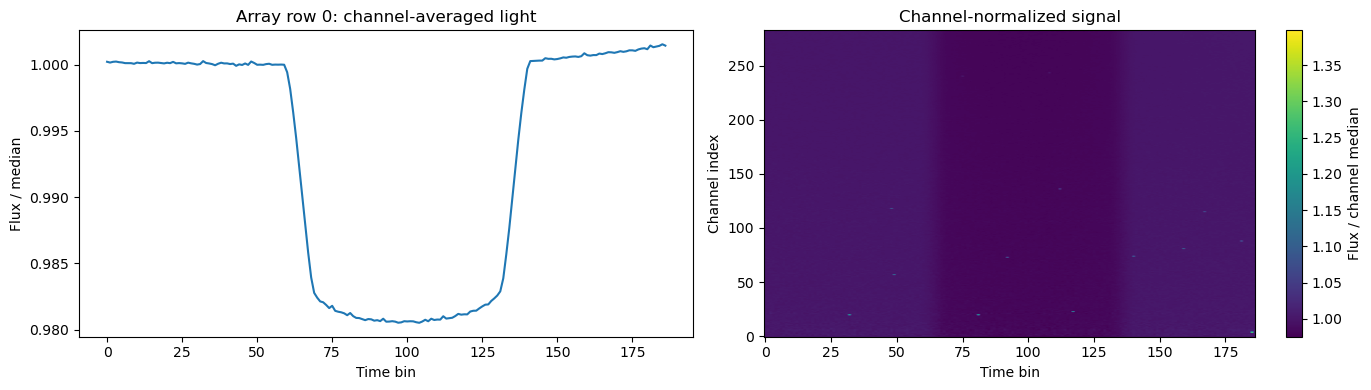

In [39]:
curve = np.mean(signal, axis=1)
assert np.isfinite(signal).all(), 'Inspect missing values before fitting.'
channel_medians = np.median(signal, axis=0)
normalized = np.divide(signal, channel_medians, out=np.full_like(signal, np.nan), where=channel_medians != 0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(curve / np.median(curve))
axes[0].set(title=f'Array row {PLANET_INDEX}: channel-averaged light', xlabel='Time bin', ylabel='Flux / median')
im = axes[1].imshow(normalized.T, aspect='auto', origin='lower')
axes[1].set(title='Channel-normalized signal', xlabel='Time bin', ylabel='Channel index')
fig.colorbar(im, ax=axes[1], label='Flux / channel median')
plt.tight_layout()
plt.show()

## 4. Smooth noise and locate the transit
Savitzky?Golay smoothing fits a small polynomial in a moving window. The original model uses a 31-bin, degree-2 window for detecting boundaries and an 11-bin, degree-3 window for fitting depth. Wide windows suppress noise but may blur ingress and egress.

Phase detection finds the minimum in the search region, then the largest absolute gradient before and after that minimum. This is a heuristic: noise, drift, and a clipped transit can create misleading boundaries.

In [40]:
class Config:
    SCALE = 0.927
    MODEL_PHASE_DETECTION_SLICE = slice(0, 186)
    MODEL_OPTIMIZATION_DELTA = 7
    MODEL_POLYNOMIAL_DEGREE = 3

config = Config()

In [41]:
class TransitModel:
    def __init__(self, config):
        self.cfg = config

    def _phase_detector(self, signal):
        search_slice = self.cfg.MODEL_PHASE_DETECTION_SLICE
        min_index = np.argmin(signal[search_slice]) + search_slice.start

        signal1 = signal[:min_index]
        signal2 = signal[min_index:]

        grad1 = np.abs(np.gradient(signal1))
        phase1 = np.argmax(grad1)

        grad2 = np.abs(np.gradient(signal2))
        phase2 = np.argmax(grad2) + min_index

        return phase1, phase2

    def _objective_function(self, s, signal, phase1, phase2, middle):
        delta = self.cfg.MODEL_OPTIMIZATION_DELTA
        power = self.cfg.MODEL_POLYNOMIAL_DEGREE
        off=7

        middle_point = (np.floor((phase2-phase1)/2)+phase1).astype(int)
        half_size = (np.floor(middle*(phase2-phase1)/2)).astype(int)
        #print(phase1, middle_point-half_size, middle_point, middle_point+half_size, phase2)


        begin = phase1-off
        end = phase2+off
        '''
        # Handle edge cases
        if begin < 1:
            begin = 1
            begin_pad = np.repeat(signal[0], 20)
        else:
            begin_pad = np.array([])

        if end > 186:
            end = 186
            end_pad = np.repeat(signal[186], 20)
        else:
            end_pad = np.array([])

        # Construct y
        y = np.concatenate([
            begin_pad,
            signal[:begin],
            signal[middle_point - half_size : middle_point + half_size] * (1 + s),
            signal[end:],
            end_pad
        ])
        '''


        if begin<1:
            begin=1
        if end>186:
            end=186
        # Construct y
        y = np.concatenate([
            signal[:begin],
            signal[middle_point - half_size : middle_point + half_size] * (1 + s),
            signal[end:]
        ])


        x = np.arange(len(y))

        coeffs = np.polyfit(x, y, deg=power)
        poly = np.poly1d(coeffs)
        error = np.abs(poly(x) - y).mean()

        return error

    def predict(self, single_preprocessed_signal, middle):
        # Step 1: Reduce to 1D signal
        signal_1d = single_preprocessed_signal[:, :].mean(axis=1)

        # Step 2: Denoise for detection and fitting
        signal_1d_detection = savgol_filter(signal_1d, 31, 2)
        signal_1d = savgol_filter(signal_1d, 11, 3)

        # Step 3: Detect phases
        phase1, phase2 = self._phase_detector(signal_1d_detection)


        # Step 4: Check for edge/cut-off cases
        if phase1 < 15 or phase2 > 174:
            # Fallback to min-max depth estimation
            depth_estimate = (signal_1d.max() - signal_1d.min())/(signal_1d.max())
            return depth_estimate

        # Step 5: Clamp for optimization bounds
        phase1 = max(self.cfg.MODEL_OPTIMIZATION_DELTA, phase1)
        phase2 = min(len(signal_1d) - self.cfg.MODEL_OPTIMIZATION_DELTA - 1, phase2)

        # Step 6: Optimize
        result = minimize(
            fun=self._objective_function,
            x0=[0.0001],
            args=(signal_1d, phase1, phase2, middle),
            method="Nelder-Mead"
        )


        return result.x[0]


    def predict_all(self, preprocessed_signals, middle):
        predictions = [
            self.predict(preprocessed_signal, middle)
            for preprocessed_signal in tqdm(preprocessed_signals)
        ]
        return np.array(predictions) * self.cfg.SCALE

Detected boundaries: (65, 135)


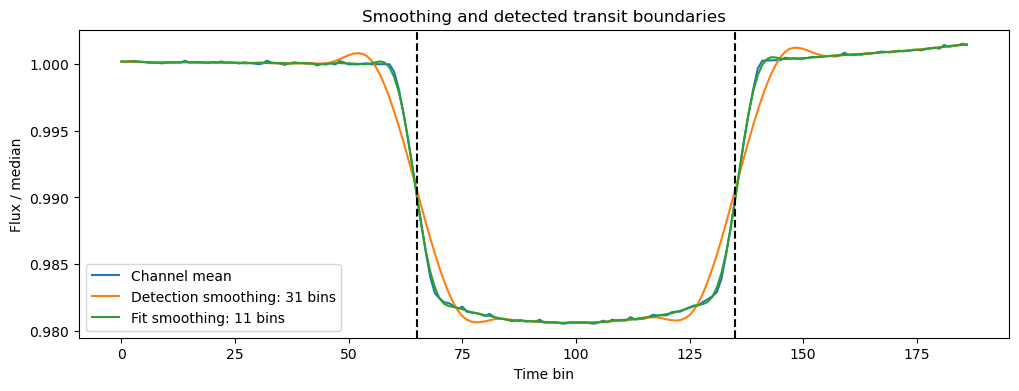

In [42]:
model = TransitModel(config)
detection_curve = savgol_filter(curve, 31, 2)
fitting_curve = savgol_filter(curve, 11, 3)
# The original detector needs at least two samples on either side of its minimum.
minimum = int(np.argmin(detection_curve[config.MODEL_PHASE_DETECTION_SLICE]))
valid_detection = 2 <= minimum <= len(curve) - 2
phases = model._phase_detector(detection_curve) if valid_detection else None
print('Detected boundaries:', phases)
fig, ax = plt.subplots(figsize=(12, 4))
for values, name in [(curve, 'Channel mean'), (detection_curve, 'Detection smoothing: 31 bins'), (fitting_curve, 'Fit smoothing: 11 bins')]:
    ax.plot(values / np.median(curve), label=name)
if phases:
    for phase in phases: ax.axvline(phase, color='black', linestyle='--')
ax.set(xlabel='Time bin', ylabel='Flux / median', title='Smoothing and detected transit boundaries')
ax.legend()
plt.show()

## 5. Understand the fitted depth
The model multiplies the central part of the dip by `(1 + s)` and fits a cubic baseline to that corrected interior plus the outside-transit samples. It chooses `s` to minimize mean absolute baseline residuals using Nelder?Mead. Samples around the transit edges are excluded. The original objective compresses retained samples onto consecutive indices, rather than fitting at their original times.

For a simple flat transit, fractional depth is approximately `s` for small dips (more exactly `s / (1 + s)`). The supplied model uses `s` directly and then multiplies by an empirical factor of **0.927**. That factor is retained to reproduce the supplied baseline; its justification cannot be established from this array alone.

When boundaries are too close to an edge, the model uses `(maximum ? minimum) / maximum` instead. This fallback may include drift and noise. The curve below shows the objective being optimized, not a probability or confidence interval.

Scaled baseline estimate: 0.018410; route: optimized interior


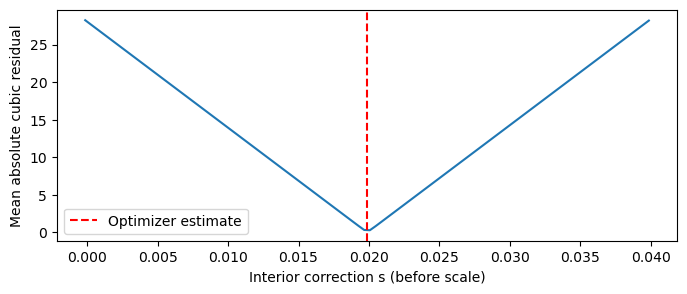

In [43]:
def estimate_depth(one_signal, middle=MIDDLE):
    averaged = one_signal.mean(axis=1)
    detection = savgol_filter(averaged, 31, 2)
    minimum = int(np.argmin(detection[config.MODEL_PHASE_DETECTION_SLICE]))
    if minimum < 2 or minimum > len(averaged) - 2:
        smooth = savgol_filter(averaged, 11, 3)
        return (smooth.max() - smooth.min()) / smooth.max() * config.SCALE, 'boundary fallback'
    p1, p2 = model._phase_detector(detection)
    route = 'edge fallback' if p1 < 15 or p2 > 174 else 'optimized interior'
    return model.predict(one_signal, middle) * config.SCALE, route

depth, route = estimate_depth(signal)
print(f'Scaled baseline estimate: {depth:.6f}; route: {route}')
if phases and route == 'optimized interior':
    p1 = max(config.MODEL_OPTIMIZATION_DELTA, phases[0])
    p2 = min(len(curve) - config.MODEL_OPTIMIZATION_DELTA - 1, phases[1])
    unscaled = depth / config.SCALE
    offsets = np.linspace(max(-0.01, unscaled - 0.02), unscaled + 0.02, 100)
    residuals = [model._objective_function(np.array([s]), fitting_curve, p1, p2, MIDDLE) for s in offsets]
    plt.figure(figsize=(8, 3))
    plt.plot(offsets, residuals)
    plt.axvline(unscaled, color='red', linestyle='--', label='Optimizer estimate')
    plt.xlabel('Interior correction s (before scale)')
    plt.ylabel('Mean absolute cubic residual')
    plt.legend()
    plt.show()

## 6. Small batch: compare shapes and estimated depths
Inspect a few planets before running all 900. Differences in estimates are not automatically errors: actual transits can have different depths. Overlaying median-normalized curves reveals drift, timing shifts, and clipped dips.

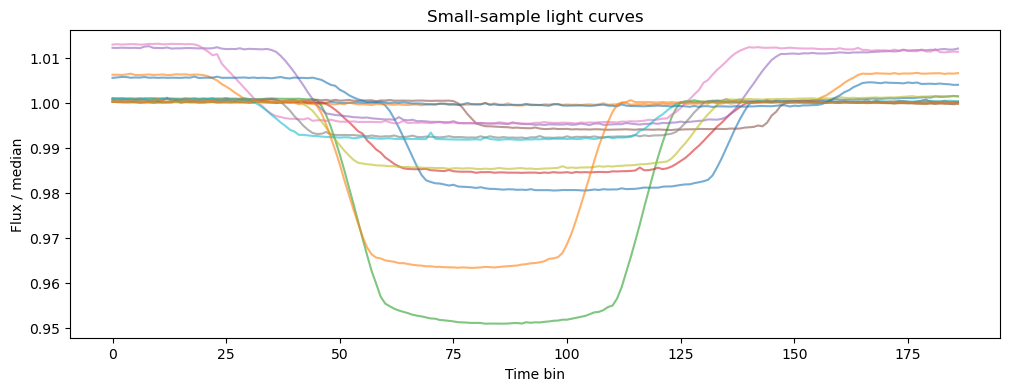

,array_index,estimated_depth,route
0,0,0.018410,optimized interior
1,1,0.006260,optimized interior
2,2,0.048162,optimized interior
3,3,0.014725,optimized interior
4,4,0.014874,optimized interior
5,5,0.005817,optimized interior
6,6,0.015995,optimized interior
7,7,0.007699,optimized interior
8,8,0.014104,optimized interior
9,9,0.007912,optimized interior


In [44]:
indices = np.arange(min(EXPERIMENT_COUNT, len(signals)))
rows = []
fig, ax = plt.subplots(figsize=(12, 4))
for index in indices:
    one = np.asarray(signals[index])
    value, method = estimate_depth(one)
    rows.append({'array_index': int(index), 'estimated_depth': value, 'route': method})
    averaged = one.mean(axis=1)
    ax.plot(averaged / np.median(averaged), alpha=0.6, label=str(index))
ax.set(xlabel='Time bin', ylabel='Flux / median', title='Small-sample light curves')
plt.show()
summary = pd.DataFrame(rows)
display(summary)

## 7. Experiment: how much transit interior should we use?
`middle` controls how much of the detected interior participates in the fit. Try 0.25 through 0.75. A stable estimate across these settings is reassuring but does not prove accuracy. Large changes suggest a shape mismatch or sensitivity to the chosen boundaries.

,middle,estimated_depth
0,0.25,0.018554
1,0.35,0.018480
2,0.45,0.018410
3,0.55,0.018322
4,0.75,0.018141


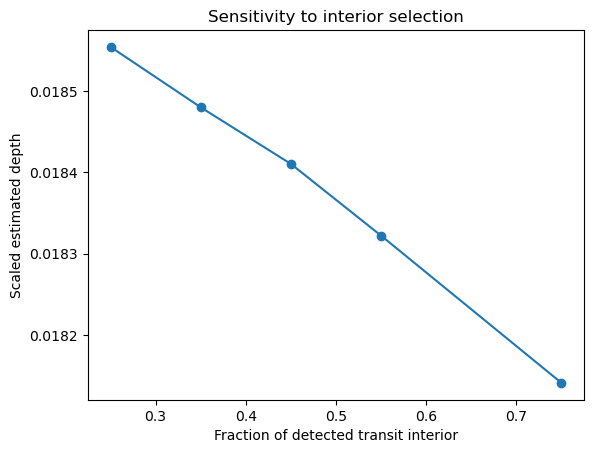

In [45]:
middle_values = [0.25, 0.35, 0.45, 0.55, 0.75]
window_results = pd.DataFrame([
    {'middle': middle, 'estimated_depth': estimate_depth(signal, middle)[0]}
    for middle in middle_values
])
display(window_results)
plt.plot(window_results.middle, window_results.estimated_depth, marker='o')
plt.xlabel('Fraction of detected transit interior')
plt.ylabel('Scaled estimated depth')
plt.title('Sensitivity to interior selection')
plt.show()

## 8. Experiment: smoothing choices
Overlay several windows and inspect whether the dip shape survives. Short windows keep detail and noise; long windows can flatten the dip. This cell is a visual experiment and does not change the baseline model.

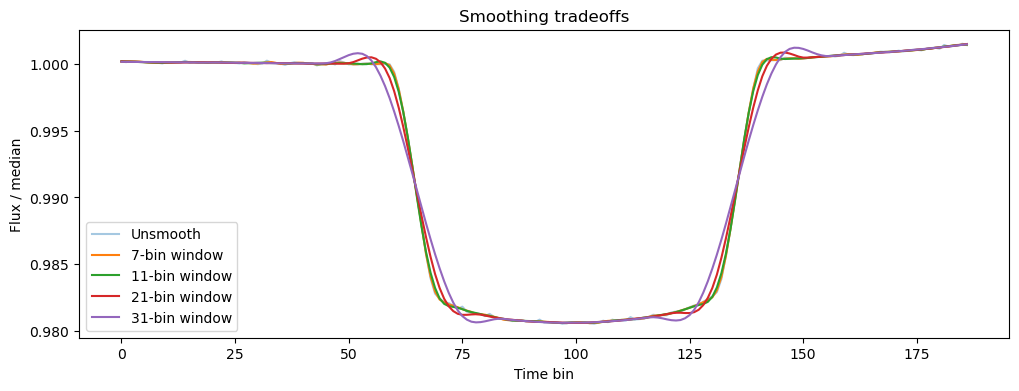

In [46]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(curve / np.median(curve), alpha=0.4, label='Unsmooth')
for window in [7, 11, 21, 31]:
    ax.plot(savgol_filter(curve, window, 2) / np.median(curve), label=f'{window}-bin window')
ax.set(xlabel='Time bin', ylabel='Flux / median', title='Smoothing tradeoffs')
ax.legend()
plt.show()

## 9. Experiment: PCA reconstruction of one planet
The enhanced source model reconstructs signals with PCA, SVD, and NMF and combines resulting depth estimates. PCA/SVD represent data using a smaller set of shared patterns; NMF uses nonnegative factors. Reconstruction might reduce noise, but it might also remove real spectral features or change the dip.

Here we start with a smaller, inspectable PCA experiment: **time bins are samples and channels are features for one planet**. This differs from the original enhanced model, which flattens whole planets and fits across planets. We normalize channels and reconstruct at several ranks. Because we fit and reconstruct the same signal, the error below measures reconstruction fidelity, not predictive generalization.

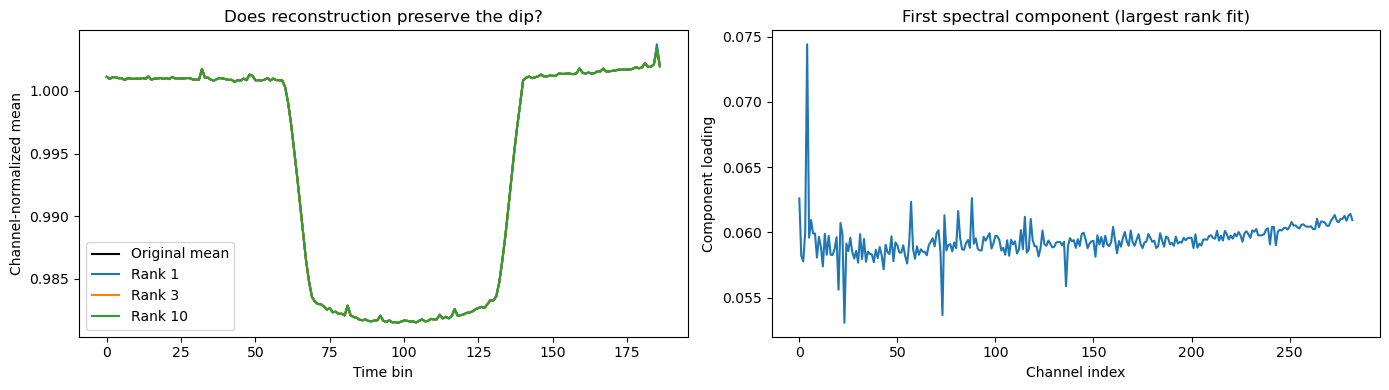

,rank,explained_variance,reconstruction_mse
0,1,0.907381,0.000008
1,3,0.964115,0.000003
2,10,0.984041,0.000001


In [47]:
ranks = [1, 3, 10]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(normalized.mean(axis=1), color='black', label='Original mean')
pca_rows = []
for rank in ranks:
    reducer = PCA(n_components=min(rank, *normalized.shape), random_state=42)
    reconstructed = reducer.inverse_transform(reducer.fit_transform(normalized))
    axes[0].plot(reconstructed.mean(axis=1), label=f'Rank {rank}')
    pca_rows.append({'rank': rank, 'explained_variance': reducer.explained_variance_ratio_.sum(), 'reconstruction_mse': np.mean((normalized - reconstructed) ** 2)})
axes[0].set(xlabel='Time bin', ylabel='Channel-normalized mean', title='Does reconstruction preserve the dip?')
axes[0].legend()
axes[1].plot(reducer.components_[0])
axes[1].set(xlabel='Channel index', ylabel='Component loading', title='First spectral component (largest rank fit)')
plt.tight_layout()
plt.show()
display(pd.DataFrame(pca_rows))

## 10. Optional ground-truth evaluation
No training CSV is supplied here. Visualizations and model estimates above do not require it.

If you add labels, set `TRAIN_CSV` and explicitly confirm array-row alignment. We average spectral labels to compare with this scalar-depth model. This cannot assess wavelength-dependent prediction quality. Scale tuning or selecting model settings must use a training/validation split; report final performance on untouched data, with preprocessing learned only from training samples.

In [48]:
TRAIN_CSV = PROJECT_ROOT / 'data' / 'ariel-data-challenge-2025' / 'train.csv'
CONFIRM_ROW_ALIGNMENT = False  # Set True only after checking planet IDs/order externally.
if TRAIN_CSV.is_file() and CONFIRM_ROW_ALIGNMENT:
    labels = pd.read_csv(TRAIN_CSV, index_col='planet_id')
    if len(labels) < len(signals):
        raise ValueError('Not enough label rows for the supplied array.')
    targets = labels.iloc[indices].mean(axis=1).to_numpy()
    estimates = summary.estimated_depth.to_numpy()
    print('Sample MAE:', np.mean(np.abs(estimates - targets)))
    print('Sample RMSE:', np.sqrt(np.mean((estimates - targets) ** 2)))
    plt.scatter(targets, estimates)
    lo, hi = min(targets.min(), estimates.min()), max(targets.max(), estimates.max())
    plt.plot([lo, hi], [lo, hi], '--', color='gray')
    plt.xlabel('Mean labelled transit depth')
    plt.ylabel('Estimated depth')
    plt.show()
else:
    print('Skipping labels: supply train.csv and confirm row alignment to enable evaluation.')

Skipping labels: supply train.csv and confirm row alignment to enable evaluation.


## 11. Ideas to develop
1. Compare fitting a baseline at the original sample times with the source's compressed time indices.
2. Compare PCA, SVD, and NMF on a small held-out set an record it( don't forget this like I did earlier althoguhg PCA I know will be best)
3. Estimate uncertainty by resampling residuals or repeated exposures rather than using one fixed competition sigma.